In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import (
    classification_report,
    f1_score,
    accuracy_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [81]:
df = pd.read_excel("Online Retail.xlsx", engine="openpyxl")
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [82]:
print("Unique customers:", df["CustomerID"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique countries:", df["Country"].nunique())
print(f"Date Range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

print("\nColumn information:")
df.info()

Unique customers: 4372
Unique products: 4070
Unique countries: 38
Date Range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [83]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [84]:
quality_report = pd.Series({
    "Total rows": len(df),
    "Missing CustomerID": df["CustomerID"].isna().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Negative Quantity": (df["Quantity"] < 0).sum(),
    "Zero Quantity": (df["Quantity"] == 0).sum(),
    "Non-positive UnitPrice": (df["UnitPrice"] <= 0).sum(),
    "Cancelled invoices": df["InvoiceNo"].astype(str).str.startswith("C").sum()
})

display(quality_report.to_frame("Count"))

,Count
Total rows,541909
Missing CustomerID,135080
Duplicate rows,5268
Negative Quantity,10624
Zero Quantity,0
Non-positive UnitPrice,2517
Cancelled invoices,9288


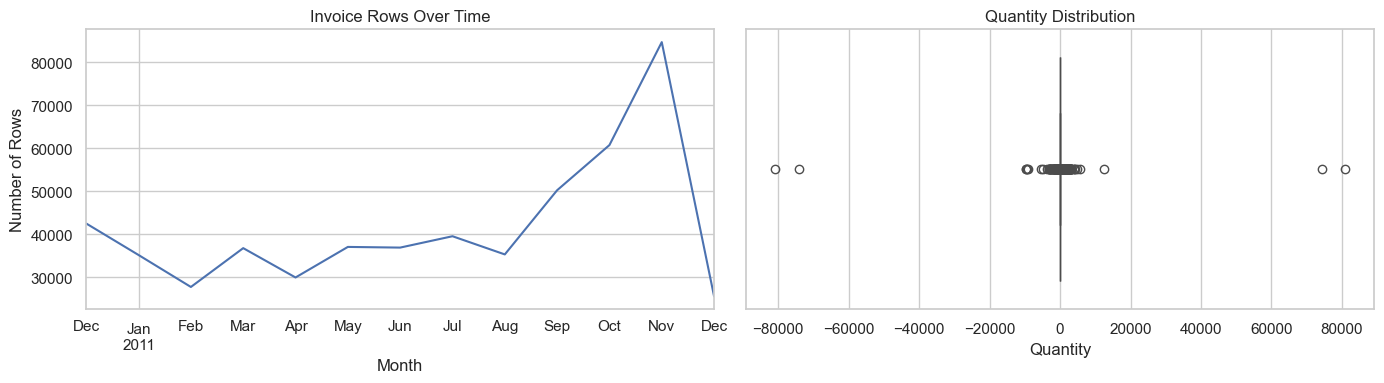

In [85]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df.groupby(df["InvoiceDate"].dt.to_period("M")).size().plot(
    ax=axes[0]
)
axes[0].set_title("Invoice Rows Over Time")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Rows")

sns.boxplot(data=df, x="Quantity", ax=axes[1])
axes[1].set_title("Quantity Distribution")

plt.tight_layout()
plt.show()

In [86]:
df_clean = df.dropna(subset=["CustomerID"]).copy()
missing_id_removed = len(df) - len(df_clean)

cancelled = df_clean["InvoiceNo"].astype(str).str.startswith("C")
cancelled_removed = cancelled.sum()
df_clean = df_clean[~cancelled].copy()

invalid = (df_clean["Quantity"] <= 0) | (df_clean["UnitPrice"] <= 0)
invalid_removed = invalid.sum()
df_clean = df_clean[~invalid].copy()

duplicates_removed = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

print(f"Original rows: {len(df)}")
print(f"Missing CustomerID: {missing_id_removed}")
print(f"Canceled invoice rows: {cancelled_removed}")
print(f"Invalid quantity/price rows: {invalid_removed}")
print(f"Duplicate rows: {duplicates_removed}")
print(f"Cleaned rows: {len(df_clean)}")
print(f"Total removed rows: {len(df) - len(df_clean)}")

Original rows: 541909
Missing CustomerID: 135080
Canceled invoice rows: 8905
Invalid quantity/price rows: 40
Duplicate rows: 5192
Cleaned rows: 392692
Total removed rows: 149217


In [87]:
df_clean["LineRevenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

total_revenue = df_clean["LineRevenue"].sum()

print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £8,887,208.89


In [88]:
cutoff_date = pd.Timestamp("2011-09-01")
future_end_date = pd.Timestamp("2011-12-01")

df_hist = df_clean[
    df_clean["InvoiceDate"] < cutoff_date
].copy()

df_future = df_clean[
    (df_clean["InvoiceDate"] >= cutoff_date) &
    (df_clean["InvoiceDate"] < future_end_date)
].copy()

print("Historical period:", df_hist["InvoiceDate"].min(),
      "to", df_hist["InvoiceDate"].max())

print("Future period:", df_future["InvoiceDate"].min(),
      "to", df_future["InvoiceDate"].max())

Historical period: 2010-12-01 08:26:00 to 2011-08-31 17:16:00
Future period: 2011-09-01 08:25:00 to 2011-11-30 17:37:00


In [89]:
hist_agg = df_hist.groupby("CustomerID").agg(
    TotalSpending=("LineRevenue", "sum"),
    PurchaseFrequency=("InvoiceNo", "nunique"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    LastPurchaseDate=("InvoiceDate", "max")
).reset_index()

hist_agg["Recency"] = (
    cutoff_date - hist_agg["LastPurchaseDate"]
).dt.days

hist_agg["AverageOrderValue"] = (
    hist_agg["TotalSpending"] /
    hist_agg["PurchaseFrequency"]
)

display(hist_agg.head())

,CustomerID,TotalSpending,PurchaseFrequency,TotalQuantity,UniqueProducts,LastPurchaseDate,Recency,AverageOrderValue
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,225,77183.600000
1,12347.0,2790.86,5,1590,82,2011-08-02 08:48:00,29,558.172000
2,12348.0,1487.24,3,2124,22,2011-04-05 10:47:00,148,495.746667
3,12350.0,334.40,1,197,17,2011-02-02 16:01:00,210,334.400000
4,12352.0,1561.81,5,254,26,2011-03-22 16:08:00,162,312.362000


In [90]:
future_spending = df_future.groupby("CustomerID").agg(
    FutureSpending=("LineRevenue", "sum")
).reset_index()

reg_data = hist_agg.merge(
    future_spending,
    on="CustomerID",
    how="left"
)

reg_data["FutureSpending"] = (
    reg_data["FutureSpending"].fillna(0)
)

print("Customers in historical data:", len(hist_agg))
print("Customers with future purchases:", len(future_spending))

display(reg_data.head())

Customers in historical data: 3317
Customers with future purchases: 2851


,CustomerID,TotalSpending,PurchaseFrequency,TotalQuantity,UniqueProducts,LastPurchaseDate,Recency,AverageOrderValue,FutureSpending
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,225,77183.600000,0.00
1,12347.0,2790.86,5,1590,82,2011-08-02 08:48:00,29,558.172000,1294.32
2,12348.0,1487.24,3,2124,22,2011-04-05 10:47:00,148,495.746667,310.00
3,12350.0,334.40,1,197,17,2011-02-02 16:01:00,210,334.400000,0.00
4,12352.0,1561.81,5,254,26,2011-03-22 16:08:00,162,312.362000,944.23


In [91]:
features = [
    "TotalSpending",
    "PurchaseFrequency",
    "TotalQuantity",
    "UniqueProducts",
    "Recency",
    "AverageOrderValue"
]

X = reg_data[features].copy()
y_reg = reg_data["FutureSpending"].copy()

X_train, X_val, y_reg_train, y_reg_val = train_test_split(
    X,
    y_reg,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Train size:", len(X_train))
print("Validation size:", len(X_val))

Train size: 2653
Validation size: 664


In [92]:
t1, t2 = X_train["TotalSpending"].quantile([0.33, 0.66])

def define_segment(spending):
    if spending <= t1:
        return "Low"
    elif spending <= t2:
        return "Medium"
    return "High"

y_class_train = X_train["TotalSpending"].apply(define_segment)
y_class_val = X_val["TotalSpending"].apply(define_segment)

classification_features = [
    "PurchaseFrequency",
    "TotalQuantity",
    "UniqueProducts",
    "Recency",
    "AverageOrderValue"
]

X_class_train = X_train[classification_features].copy()
X_class_val = X_val[classification_features].copy()

print("Training class distribution:")
print(y_class_train.value_counts(normalize=True).round(3))

print("\nValidation class distribution:")
print(y_class_val.value_counts(normalize=True).round(3))

Training class distribution:
TotalSpending
High      0.34
Low       0.33
Medium    0.33
Name: proportion, dtype: float64

Validation class distribution:
TotalSpending
High      0.357
Medium    0.337
Low       0.306
Name: proportion, dtype: float64


In [93]:
def make_preprocessor():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

clf_preprocessor = make_preprocessor()
reg_preprocessor = make_preprocessor()

In [94]:
baseline_clf = Pipeline([
    ("preprocessor", clf_preprocessor),
    ("model", DummyClassifier(strategy="prior"))
])

baseline_clf.fit(X_class_train, y_class_train)

baseline_preds = baseline_clf.predict(X_class_val)

print(classification_report(
    y_class_val,
    baseline_preds,
    zero_division=0
))

              precision    recall  f1-score   support

        High       0.36      1.00      0.53       237
         Low       0.00      0.00      0.00       203
      Medium       0.00      0.00      0.00       224

    accuracy                           0.36       664
   macro avg       0.12      0.33      0.18       664
weighted avg       0.13      0.36      0.19       664



In [95]:
clf_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(),
    "RBF SVM": SVC(
        kernel="rbf",
        random_state=RANDOM_STATE
    )
}

results_class = []

for name, model in clf_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", model)
    ])

    pipeline.fit(X_class_train, y_class_train)
    preds = pipeline.predict(X_class_val)

    results_class.append({
        "Model": name,
        "Accuracy": accuracy_score(y_class_val, preds),
        "Macro-F1": f1_score(
            y_class_val, preds,
            average="macro",
            zero_division=0
        ),
        "Weighted-F1": f1_score(
            y_class_val, preds,
            average="weighted",
            zero_division=0
        )
    })

df_results_class = pd.DataFrame(results_class).sort_values(
    "Macro-F1",
    ascending=False
)

display(df_results_class.round(4))

,Model,Accuracy,Macro-F1,Weighted-F1
2,Random Forest,0.9819,0.9823,0.9820
1,Decision Tree,0.9684,0.9690,0.9684
3,KNN,0.9142,0.9154,0.9147
0,Logistic Regression,0.8916,0.8931,0.8927
4,RBF SVM,0.8916,0.8924,0.8929


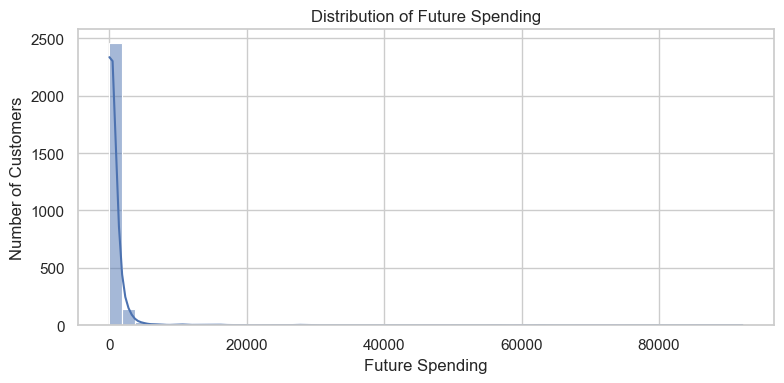

Customers with zero future spending: 0.438


In [96]:
plt.figure(figsize=(8, 4))

sns.histplot(
    y_reg_train,
    bins=50,
    kde=True
)

plt.title("Distribution of Future Spending")
plt.xlabel("Future Spending")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

print("Customers with zero future spending:",
      (y_reg_train == 0).mean().round(3))

In [97]:
baseline_reg = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", DummyRegressor(strategy="median"))
])

baseline_reg.fit(X_train, y_reg_train)

baseline_reg_preds = baseline_reg.predict(X_val)

print("Baseline MAE:",
      round(mean_absolute_error(y_reg_val, baseline_reg_preds), 2))

print("Baseline RMSE:",
      round(np.sqrt(mean_squared_error(y_reg_val, baseline_reg_preds)), 2))

print("Baseline R2:",
      round(r2_score(y_reg_val, baseline_reg_preds), 4))

Baseline MAE: 995.2
Baseline RMSE: 6448.07
Baseline R2: -0.0175


In [98]:
reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsRegressor(),
    "Kernel Ridge (RBF)": KernelRidge(
        kernel="rbf"
    )
}

results_reg = []

for name, model in reg_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_reg_train)
    preds = pipeline.predict(X_val)

    results_reg.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_val, preds),
        "RMSE": np.sqrt(mean_squared_error(y_reg_val, preds)),
        "R2": r2_score(y_reg_val, preds)
    })

df_results_reg = pd.DataFrame(results_reg).sort_values("RMSE")

display(df_results_reg.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,748.039,3817.146,0.643
1,Ridge,747.929,3822.295,0.642
2,Random Forest,834.377,4365.800,0.534
3,Gradient Boosting,801.173,4577.780,0.487
4,KNN,836.868,5149.194,0.351
5,Kernel Ridge (RBF),903.900,6371.727,0.006


In [99]:
lr_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", LinearRegression())
])

param_dist = {
    "model__fit_intercept": [True, False],
    "model__positive": [True, False]
}

search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=param_dist,
    n_iter=4,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

search.fit(X_train, y_reg_train)

best_lr = search.best_estimator_
tuned_preds = best_lr.predict(X_val)

print("Best parameters:", search.best_params_)
print("Validation RMSE:",
      round(np.sqrt(mean_squared_error(y_reg_val, tuned_preds)), 2))
print("Validation MAE:",
      round(mean_absolute_error(y_reg_val, tuned_preds), 2))

Best parameters: {'model__positive': True, 'model__fit_intercept': True}
Validation RMSE: 4292.95
Validation MAE: 819.09


In [100]:
lr_model = best_lr.named_steps["model"]

feature_names = (
    best_lr.named_steps["preprocessor"].get_feature_names_out()
)

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.coef_
})

coefficients["AbsCoefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    "AbsCoefficient",
    ascending=False
)

display(coefficients.round(4))

,Feature,Coefficient,AbsCoefficient
0,TotalSpending,1904.9358,1904.9358
2,TotalQuantity,484.8104,484.8104
1,PurchaseFrequency,177.4848,177.4848
3,UniqueProducts,138.9178,138.9178
4,Recency,61.6351,61.6351
5,AverageOrderValue,0.0000,0.0000


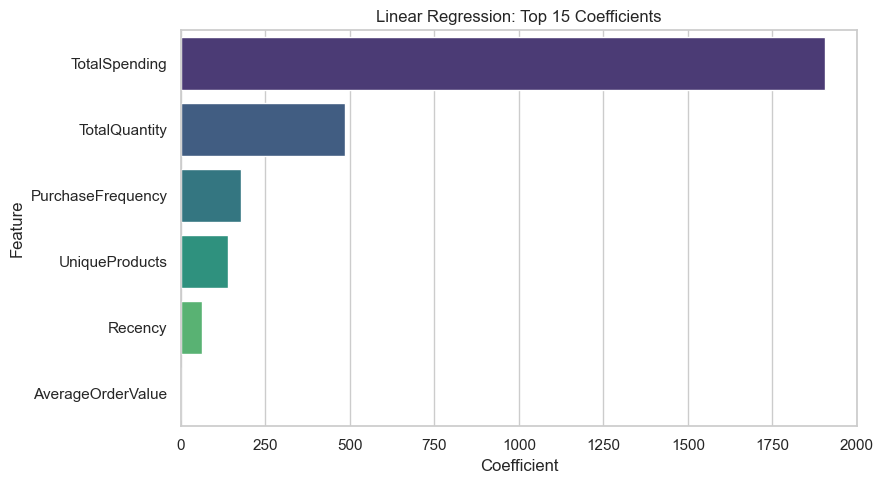

In [101]:
top_coefficients = coefficients.head(15)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature",
    palette="viridis",
    hue="Feature",
    legend=False
)

plt.title("Linear Regression: Top 15 Coefficients")
plt.tight_layout()
plt.show()

In [102]:
error_analysis = pd.DataFrame({
    "CustomerID": reg_data.loc[X_val.index, "CustomerID"],
    "Actual": y_reg_val,
    "Predicted": tuned_preds
}, index=X_val.index)

error_analysis["AbsError"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

top_errors = error_analysis.sort_values(
    "AbsError",
    ascending=False
).head(10)

display(top_errors.round(2))

,CustomerID,Actual,Predicted,AbsError
2850,17450.0,107218.05,36276.70,70941.35
3213,18102.0,117634.53,52346.78,65287.75
0,12346.0,0.00,38458.82,38458.82
45,12415.0,25768.37,45967.56,20199.19
1927,15749.0,0.00,18706.14,18706.14
1978,15838.0,19489.58,6525.95,12963.63
1784,15482.0,8951.46,782.65,8168.81
874,13881.0,9621.26,3357.10,6264.16
1113,14298.0,15297.86,21220.55,5922.69
346,12931.0,9525.26,14998.96,5473.70
